# Redes Neurais Artificiais — Projeto Prático 2.1

- Redes Neurais Artificiais 2026.2
- Profa. Elloá B. Guedes (ebgcosta@uea.edu.br)
- http://github.com/elloa

### Equipe

- João Victor Mattos Lopes (github.com/Jaum36) - 2315080034
- Gabriel Augusto da Eira Corrêa Benayon (github.com/devgabrielbenayon) - 2415310049

Identificador dos exemplos: (4 + 9) % 4 = 1. 

In [6]:
# Numpy obrigatório para manipulação de arrays e matrizes
import numpy as np

import matplotlib.pyplot as plt
import random 
import math
import pandas as pd
import prettytable as pt

# Só usar pra cálculo de métrica de desempenho
# import sklearn


In [7]:
identificador = (4 + 9) % 4

dados = np.load(f"data/data{identificador}20262.txt").reshape(-1, 3)
X = dados[:, :2]
y = dados[:, 2]

# Parte I - Resolvendo um Problema Linearmente Separável

In [ ]:
class Perceptron:
  def __init__(self, taxa_aprendizado=0.1, intervalo_pesos=(-0.5, 0.5)):
    self.taxa_aprendizado = taxa_aprendizado
    self.intervalo_pesos = intervalo_pesos
    self.w = None  # [viés, w1, w2]

  def _adicionar_bias(self, X):
    return np.hstack((np.ones((X.shape[0], 1)), X))

  def _degrau(self, u):
    return np.where(u >= 0, 1, 0)

  def train(self, X, y, max_epocas=None, embaralhar=False, verbose=True):
    Xb = self._adicionar_bias(X)
    self.w = np.random.uniform(self.intervalo_pesos[0], self.intervalo_pesos[1], Xb.shape[1])

    if verbose:
      print(f"Vetor inicial de pesos [viés, w1, w2]: {self.w}")

    epocas = 0
    ajustes = 0

    # Sem max_epocas, treina até a convergência
    while max_epocas is None or epocas < max_epocas:
      epocas += 1
      erros = 0

      indices = np.random.permutation(len(Xb)) if embaralhar else np.arange(len(Xb))

      for i in indices:
        erro = y[i] - self._degrau(np.dot(self.w, Xb[i]))

        if erro != 0:
          self.w = self.w + self.taxa_aprendizado * erro * Xb[i]
          erros += 1
          ajustes += 1

      if erros == 0:
        break

    if verbose:
      print(f"Número total de ajustes no vetor de pesos: {ajustes}")
      print(f"Número de épocas até a convergência: {epocas}")

    return epocas, ajustes

  def predict(self, X):
    return self._degrau(np.dot(self._adicionar_bias(X), self.w))


In [9]:
dados = np.load("data/dataAll20262.txt").reshape(-1, 3)
entradas = dados[:, :2]
saida = dados[:, 2]

p = Perceptron(taxa_aprendizado=0.1, intervalo_pesos=(-0.5, 0.5))

epocas, ajustes = p.train(entradas, saida)

Vetor inicial de pesos [viés, w1, w2]: [ 0.00315544 -0.18355552  0.16901852]
Número total de ajustes no vetor de pesos: 108
Número de épocas até a convergência: 8


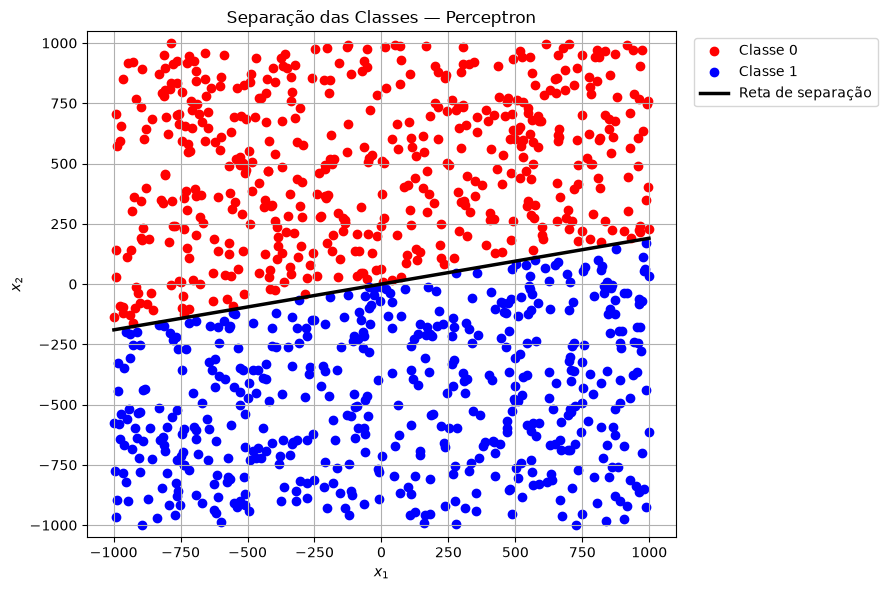

In [10]:
classe_0 = saida == 0
classe_1 = saida == 1

vies, w1, w2 = p.w

plt.figure(figsize=(9, 6))
plt.scatter(entradas[classe_0, 0], entradas[classe_0, 1], c='red', label="Classe 0")
plt.scatter(entradas[classe_1, 0], entradas[classe_1, 1], c='blue', label="Classe 1")

# Reta de separação: vies + w1*x1 + w2*x2 = 0
if w2 != 0:
  x1_reta = np.linspace(entradas[:, 0].min(), entradas[:, 0].max(), 200)
  x2_reta = -(w1 * x1_reta + vies) / w2
  plt.plot(x1_reta, x2_reta, color="black", linewidth=2.5, label="Reta de separação")
else:
  plt.axvline(-vies / w1, color="black", linewidth=2.5, label="Reta de separação")

plt.ylim(entradas[:, 1].min() - 50, entradas[:, 1].max() + 50)
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.title("Separação das Classes — Perceptron")
plt.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
plt.grid(True)
plt.tight_layout()
plt.show()